![Banner](../images/09_13_banner_rs_capstones.png)


# Fifty Years of Change in the Bangladesh Delta

The Meghna estuary, where Bangladesh's rivers meet the Bay of Bengal, is one of the most
geomorphologically active places on Earth: monsoon floods carry roughly one billion tonnes of
sediment a year past this point, building and eroding *char* (sandbar) islands from one season
to the next.


## Overview

NASA's own ["World of Change: Padma
River"](https://science.nasa.gov/earth/earth-observatory/world-of-change/padma-river/) tells the
same story a little upstream; here we build an equivalent product ourselves, from the full
Landsat archive, over the stretch of river around Bhola and Lakshmipur.

This notebook downloads **every available low-cloud Landsat scene** covering the AOI for each
year of the last half-century - not a handful of hand-picked dates. The AOI spans four Landsat
WRS-2 tiles, so every date needs a real 4-scene mosaic; we then resample every year to one common
100 m grid and clip it to the exact area below, so 1972's MSS and 2024's OLI-2 end up on
identical pixels. The result is a year-by-year animation and a 50-year land loss/gain map.


## Setup

Libraries, a reachability check for Planetary Computer, and the two folders this notebook uses: `DATA` for downloaded scenes and `OUT_DIR` for the animation.

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Imports, the shared data folder, and the folder the animation GIF is written to.

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Image as IPImage

import geolattice.rsense as rs
from geolattice.rsense.get_images import get_images, search_images
from geolattice.rsense.viz.stretch import rgb as make_rgb
from geolattice.network import is_online

plt.rcParams.update({"figure.dpi": 110})
ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"),
      "| Planetary Computer reachable:", ONLINE)

# Same folder as the Landsat tutorial, so scenes already downloaded there are reused.
# get_images skips files that are already on disk.
DATA = next((p for p in (Path("../../../../Data/08_remote_sensing/08_02_optical"), Path("Data/08_remote_sensing/08_02_optical"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_02_optical"))  # shared optical data, from this folder or the repository root
DATA.mkdir(parents=True, exist_ok=True)

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)


geolattice.rsense 0.2.0.dev0 | backend: cpu | Planetary Computer reachable: True


### Data

This analysis uses a time series of satellite imagery from the Landsat archive (via Microsoft Planetary Computer) to study surface water and land change in a part of the Lower Meghna Delta, Bangladesh. 

The dataset spans from 1972 to 2024, including scenes from all five generations of Landsat sensors (MSS, TM, ETM+, OLI, OLI-2). Each year, the clearest available image during the dry-season is selected for each orbit path/row tile covering the region. The data includes processed images indicating water and land, enabling quantification of persistent and changing surface water and land areas across five decades. All data are avilable 
[here](https://www.dropbox.com/scl/fo/c7b6estcd609sp9gdwhuu/AMyl1zO3KuhaiHzB6PiwQkM?rlkey=s458rnzp553y57e02mjx01ri6&dl=0) for download. 


In [2]:
# The area from your map screenshot: the Meghna narrows between Bhola and Lakshmipur.
DELTA_AOI = (90.383256, 22.292743, 91.221131, 22.838538)      # (minlon, minlat, maxlon, maxlat)
DELTA_RES_M = 100.0                                            # final resampled resolution
DELTA_CRS = "EPSG:32646"                                        # UTM 46N, the local zone

### Finding every usable scene, 1972-2024

For each dry-season window (November-March, when monsoon cloud is lowest) and each of five
sensor generations, we search Planetary Computer for the clearest scene per year per tile, then
keep the best available sensor for each year, preferring Landsat 8/9 (OLI) and 5 (TM) over
Landsat 7 (ETM+) wherever a gap-free alternative exists, since every ETM+ scene after May 2003
carries permanent scan-line-corrector gaps. MSS (1972-1980) used a different reference grid
(WRS-1) from every later mission (WRS-2), but the same AOI search finds it regardless.


In [ ]:

# This block handles selection of relevant Landsat satellite scenes (images) covering
# the Lower Meghna Delta in Bangladesh for each year from 1972-2024, building a dictionary
# organizing the cleanest and most relevant scene per tile per year according to priority
# sensor type and cloud cover.

from collections import defaultdict

# Set up data storage locations: main data directory, plus directories for annual and 50-year stacks
DATA = next((p for p in (Path("Data/08_remote_sensing/08_11_Capstones"), Path("../../../../Data/08_remote_sensing/08_11_Capstones"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_11_Capstones"))  # capstone data, from this folder or the repository root
DELTA_OUT_ANNUAL = DATA / "bd_delta_annual"
DELTA_OUT_50YR = DATA / "bd_delta_50yr"

# Select which output directory to use (here, annual by default)
DELTA_OUT = DELTA_OUT_ANNUAL  # This could be switched if aggregation/gridding changes

# Ensure the output directory exists
DELTA_OUT.mkdir(parents=True, exist_ok=True)

# Define configuration for each Landsat sensor: collection name, platform (satellite), and relevant bands
SENSOR_CFG = {
    "OLI9": dict(collection="landsat-c2-l2", platforms=["landsat-9"], bands=["red", "green", "nir"]),
    "OLI8": dict(collection="landsat-c2-l2", platforms=["landsat-8"], bands=["red", "green", "nir"]),
    "TM5": dict(collection="landsat-c2-l2", platforms=["landsat-5"], bands=["red", "green", "nir"]),
    "ETM+": dict(collection="landsat-c2-l2", platforms=["landsat-7"], bands=["red", "green", "nir"]),
    "MSS": dict(collection="landsat-c2-l1", platforms=None, bands=["red", "green", "nir08"]),
}
# Define coverage years for each sensor
SENSOR_YEARS = {
    "OLI9": (2021, 2024), "OLI8": (2013, 2024), "TM5": (1984, 2013),
    "ETM+": (1999, 2022), "MSS": (1972, 1983)
}

# Set the location for the cached scene list. This is used to avoid re-querying the remote API every time.
scene_list_path = DATA / "scene_list.pkl"
import pickle

# Attempt to load the scene list from disk to save time if already generated previously
try:
    with open(scene_list_path, "rb") as f:
        scene_list = pickle.load(f)
    print("Loaded existing scene list from disk.")

except FileNotFoundError:
    print("Scene list not found on disk. Surveying and building scene list...")

    # Function to search Planetary Computer for dry-season (Nov–Mar) scenes for each sensor.
    # For each year and tile, finds the scene with the lowest cloud cover.
    def survey(y0, y1, collection, platforms):
        """Lowest-cloud dry-season scene per (year, tile) for one sensor generation."""
        by_year_tile = defaultdict(dict)
        # Process a few years at a time to keep API queries manageable
        for chunk0 in range(y0, y1 + 1, 3):
            chunk1 = min(chunk0 + 2, y1)
            found = search_images(
                bbox=DELTA_AOI,
                dates=(f"{chunk0}-01-01", f"{chunk1}-12-31"),
                source="planetary",
                collection=collection,
                platforms=platforms,
                limit=500,  # Large enough to cover all scenes per chunk
                quiet=True
            )
            for s in found.scenes:
                # Skip early MSS scenes without georeferencing
                if "_L1GS_" in s["id"]:
                    continue
                # Identify the scene's tile and acquisition date
                tile, dt = s["id"].split("_")[2], s["datetime"][:10]
                yr, mo = int(dt[:4]), int(dt[5:7])
                # Only consider dry-season months
                if mo not in (11, 12, 1, 2, 3):
                    continue
                # Use cloud cover; default to 100 if missing
                cloud = s.get("cloud")
                cloud = 100 if cloud is None else cloud
                # Ignore fully cloudy scenes
                if cloud >= 100:
                    continue
                # Keep the lowest-cloud scene for each (year, tile)
                cur = by_year_tile[yr].get(tile)
                if cur is None or cloud < cur[0]:
                    by_year_tile[yr][tile] = (cloud, s["id"])
        return by_year_tile

    # For all sensors, run the survey for the appropriate years
    surveys = {
        sensor: survey(*SENSOR_YEARS[sensor],
                       cfg["collection"], cfg["platforms"])
        for sensor, cfg in SENSOR_CFG.items()
    }

    # Collect all tile names ever found by any sensor, for completeness
    all_tiles = {t for s in surveys.values() for tiles in s.values() for t in tiles}

    scene_list = {}
    # For each year eligible in the entire range, select a best-available scene for each tile
    for yr in range(1972, 2025):
        picks = {}
        for tile in all_tiles:
            for sensor in SENSOR_CFG:  # Sensors checked in priority order!
                entry = surveys[sensor].get(yr, {}).get(tile)
                if entry is not None:
                    picks[tile] = (entry[1], sensor)  # store scene ID and source sensor
                    break
        if picks:
            scene_list[yr] = picks

    # Save the list so we can reload it next time rather than repeat this survey
    with open(scene_list_path, "wb") as f:
        pickle.dump(scene_list, f)
    print("Scene list built and saved to disk.")

# Count up all selected scenes and print a summary table: years found and tiles per year
n_scenes = sum(len(p) for p in scene_list.values())
print(f"{len(scene_list)} years with data, {n_scenes} scenes total, "
      f"{str(min(scene_list))}-{str(max(scene_list))}")
pd.Series({yr: len(p) for yr, p in scene_list.items()}).rename("tiles found").to_frame().T

Scene list not found on disk. Surveying and building scene list...
Scene list built and saved to disk.
46 years with data, 183 scenes total, 1972-2024


,1972,1973,1974,1975,1976,1977,1978,1979,1980,1988,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
tiles found,3,4,4,4,4,4,4,4,4,4,...,4,4,4,4,4,4,4,4,4,4


### Downloading every scene

One search-and-download pass per year (not per scene) keeps this to 53 calls instead of 180+.
`get_images` skips files already on disk, so re-running this cell after an interruption picks up
where it left off.


In [ ]:
# Set the output path for downloaded scenes and initialize a list to track download failures
DELTA_OUT = DATA / "bd_delta_annual"
failures = []

# Iterate through each year and its corresponding tile picks in the scene_list
for yr, picks in scene_list.items():
    # Organize picks by sensor type for that year
    by_sensor = defaultdict(list)
    for tile, (sid, sensor) in picks.items():
        by_sensor[sensor].append(sid)

    # For each sensor, determine which scene IDs need to be downloaded
    for sensor, ids in by_sensor.items():
        cfg = SENSOR_CFG[sensor]
        existing_ids = []  # IDs for which data is already present
        missing_ids = []   # IDs for which data needs to be downloaded
        for sid in ids:
            scene_dir = DELTA_OUT / sid
            # Assume presence of any one band file (using the first band as a check)
            band = cfg["bands"][0]
            band_fp = scene_dir / f"{band}.tif"
            if band_fp.exists():
                existing_ids.append(sid)
            else:
                missing_ids.append(sid)
        # If there are missing IDs, search for and download the necessary images
        if missing_ids:
            # Search for scenes that match the criteria
            found = search_images(
                bbox=DELTA_AOI, 
                dates=(f"{yr}-01-01", f"{yr}-12-31"),
                source="planetary",
                collection=cfg["collection"],
                platforms=cfg["platforms"],
                limit=60,
                quiet=True
            )
            # Download the images (only for missing scene IDs and specified bands)
            saved = get_images(
                DELTA_OUT, 
                search=found, 
                ids=missing_ids, 
                bands=cfg["bands"], 
                mode="clip", 
                quiet=True
            )
            # If not all requested scenes are downloaded (may be temporary catalogue issue), log failure
            if len(saved.scenes) < len(missing_ids):
                failures.append((yr, sensor, len(missing_ids) - len(saved.scenes)))

# Summarize the download operation: how many year-sensor pairs failed to fully download
print(f"Done. {len(failures)} (year, sensor) pairs returned fewer scenes than requested "
      "(a scene briefly unavailable from the catalogue) — those years just mosaic from fewer tiles.")

### Mosaic, resample to 100 m, and clip

Every scene is its own Landsat swath, tilted about 9° from north because of the satellite's
orbit, and the four tiles in one year rarely share a pixel grid with each other, let alone with
MSS's 60 m grid from the 1970s or OLI's 30 m grid from today. For each year we mosaic its 1-4
available tiles, then reproject and resample the mosaic onto one common, north-up 100 m grid
clipped to the AOI, so every year of the 53-year series ends up on identical pixels — a
requirement for the land-change map at the end of this notebook. We also compute a simple
NIR/red ratio per pixel, the one measurement every Landsat sensor since 1972 can make, as a
land/water indicator: water absorbs NIR strongly, so vegetated or bare land stands well above it.


In [ ]:

# Import necessary libraries for geospatial resampling and coordinate transformation
from rasterio.enums import Resampling
from pyproj import Transformer

# 1. Set up a transformation from geographic (lat/lon WGS84) to the delta's projected CRS
to_utm = Transformer.from_crs("EPSG:4326", DELTA_CRS, always_xy=True)

# 2. Transform the bounding box coordinates (given in longitude/latitude as DELTA_AOI)
#    to projected coordinates (usually meters) suitable for creating a standard grid.
x0, y0 = to_utm.transform(DELTA_AOI[0], DELTA_AOI[1])
x1, y1 = to_utm.transform(DELTA_AOI[2], DELTA_AOI[3])

# 3. Sort the projected coordinates to get minimum & maximum (for x and y)
minx, maxx = sorted([x0, x1])
miny, maxy = sorted([y0, y1])

# 4. Calculate the output grid's width/height in pixels given the desired spatial resolution (DELTA_RES_M)
dwidth = int(np.ceil((maxx - minx) / DELTA_RES_M))
dheight = int(np.ceil((maxy - miny) / DELTA_RES_M))

# 5. Initialize a blank xarray DataArray with the determined grid shape,
#    set its coordinate labels (x/y locations for the center of each pixel), and assign the desired CRS.
delta_grid = xr.DataArray(
    np.zeros((dheight, dwidth), "float32"),
    coords={
        "y": maxy - DELTA_RES_M / 2 - np.arange(dheight) * DELTA_RES_M,  # from top to bottom
        "x": minx + DELTA_RES_M / 2 + np.arange(dwidth) * DELTA_RES_M    # from left to right
    },
    dims=("y", "x")
).rio.write_crs(DELTA_CRS)

print("Common grid:", dict(delta_grid.sizes), "at", DELTA_RES_M, "m,", DELTA_CRS)

# 6. Prepare dictionaries to hold results per year
delta_land = {}  # Year → NIR/red ratio array (for land/water classification)
delta_rgb = {}   # Year → RGB visualization array
tiles_used = {}  # Year → How many tiles were actually used that year

# 7. For each year in the scene list:
for yr, picks in scene_list.items():
    red_tiles, green_tiles, nir_tiles = [], [], []

    # For each tile available that year, load its red, green, and NIR bands:
    for tile, (sid, sensor) in picks.items():
        d = DELTA_OUT / sid
        
        # Determine NIR band name: "nir08" for old MSS, otherwise "nir"
        nirband = "nir08" if sensor == "MSS" else "nir"
        rp = d / "red.tif"
        gp = d / "green.tif"
        np_ = d / f"{nirband}.tif"
        # Skip missing bands
        if not (rp.exists() and gp.exists() and np_.exists()):
            continue
        # Read and drop the (singleton) 'band' dimension
        red_tiles.append(rs.read(rp, masked=False).squeeze("band", drop=True))
        green_tiles.append(rs.read(gp, masked=False).squeeze("band", drop=True))
        nir_tiles.append(rs.read(np_, masked=False).squeeze("band", drop=True))

    # If at least one valid tile was found for the year, proceed
    if not red_tiles:
        continue
    tiles_used[yr] = len(red_tiles)

    # 8. Mosaic (combine) all RED, GREEN, and NIR bands from separate tiles.
    #    Assign the correct CRS, and then reproject and resample the mosaic to the common grid using bilinear resampling.
    r = rs.mosaic(red_tiles).rio.write_crs(red_tiles[0].rio.crs).rio.reproject_match(delta_grid, resampling=Resampling.bilinear)
    g = rs.mosaic(green_tiles).rio.write_crs(green_tiles[0].rio.crs).rio.reproject_match(delta_grid, resampling=Resampling.bilinear)
    n = rs.mosaic(nir_tiles).rio.write_crs(nir_tiles[0].rio.crs).rio.reproject_match(delta_grid, resampling=Resampling.bilinear)

    # 9. Set pixels with value <= 0 to NaN (invalid), and convert to float32.
    rf, gf, nf = (b.where(b > 0).astype("float32") for b in (r, g, n))

    # 10. Compute a normalized NIR/red index for each pixel: (NIR - Red)/(NIR + Red)
    #     This index helps distinguish land from water (water absorbs NIR).
    delta_land[yr] = (nf - rf) / (nf + rf + 1e-6)  # Add small epsilon to denominator for numerical safety

    # 11. Create a 3-band xarray Dataset and use it to create a RGB image for display.
    ds = xr.Dataset({"nir": nf, "red": rf, "green": gf})
    img = make_rgb(ds, ["nir", "red", "green"]).values

    # 12. Detect pixels outside the swath (those that are NaN in any band), and set to light grey (0.92)
    outside_swath = ~np.isfinite(img).all(axis=-1)
    img = np.nan_to_num(img)
    img[outside_swath] = 0.92
    delta_rgb[yr] = img

# 13. Print summary of years processed and the min/max number of tiles per year.
print(f"{len(delta_land)} years processed onto the common grid "
      f"({min(tiles_used.values())}-{max(tiles_used.values())} tiles per year).")

Common grid: {'y': 592, 'x': 871} at 100.0 m, EPSG:32646
46 years processed onto the common grid (1-4 tiles per year).


### Every year, animated

The clearest, most complete years (mostly the 1988-2001 Landsat 5 run and 2013 onward) make the
cleanest frames; a few years, 2009 and 2024 among them, only had 1-2 of the 4 tiles pass the
cloud filter in the archive, so part of the frame stays grey that year. That unevenness is the
real cost of "every available image": some years the archive simply has less to offer.


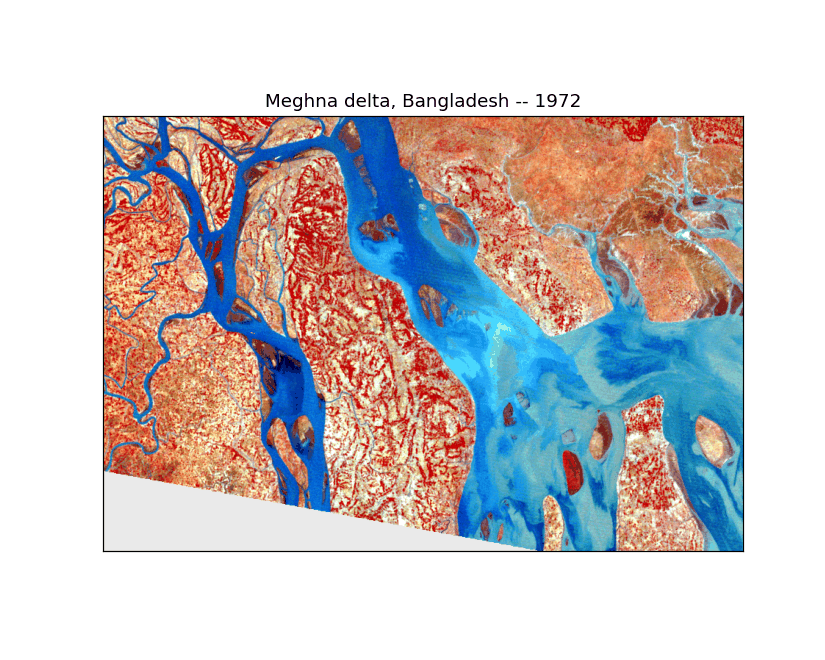

In [9]:
delta_years = sorted(delta_land)
delta_frames = [delta_rgb[y] for y in delta_years]

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(delta_frames[0], origin="upper")
ax.set_xticks([]); ax.set_yticks([])
ttl = ax.set_title("")

def _update_delta(k):
    im.set_data(delta_frames[k])
    ttl.set_text(f"Meghna delta, Bangladesh -- {delta_years[k]}")
    return im, ttl

anim = animation.FuncAnimation(fig, _update_delta, frames=len(delta_years), interval=280)
gif_path = OUT_DIR / "bangladesh_delta_1972_2024_annual.gif"
anim.save(gif_path, writer=animation.PillowWriter(fps=3.5))
plt.close(fig)
IPImage(filename=str(gif_path))

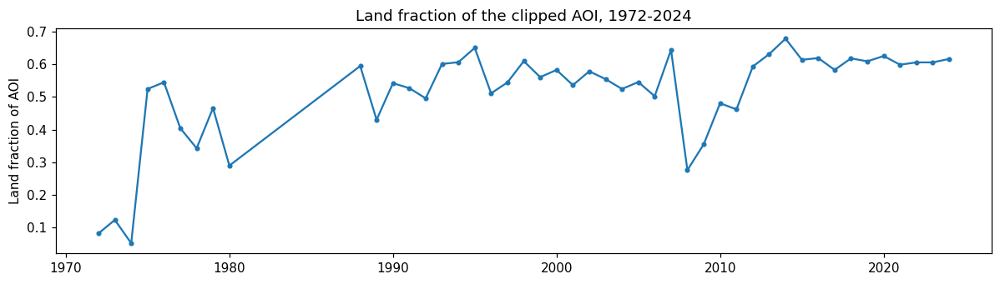

In [10]:
# How much of the clipped AOI classifies as land each year -- the same NIR/red ratio used below.
land_frac = pd.Series({yr: float((da.values > 0.1).sum()) / float(np.isfinite(da.values).sum())
                       for yr, da in delta_land.items()}).sort_index()
ax = land_frac.plot(figsize=(11, 3.2), marker="o", ms=3)
ax.set(ylabel="Land fraction of AOI", xlabel="", title="Land fraction of the clipped AOI, 1972-2024")
plt.tight_layout(); plt.show()

1972-1974 sit well below every later year, not a real three-year retreat of the delta, but
Landsat 1's earliest MSS scenes carrying a different radiometric calibration from every sensor
that followed (the same raw-DN ratio reads differently on uncorrected 1970s data). We saw the
same kind of real-data wrinkle with MOD09Q1's duplicate processing runs in Module 5. Rather than
hide it, we route around it: the land/water map below anchors its "before" period in 1975-79,
once MSS settles onto the same footing as every later mission, against "after" in 2020-24.


### Land Loss and Gain


In [11]:
# Fifty years of land loss and gain: the NIR/red ratio, averaged over five years at each end of
# the record so single-date noise and cloud edges do not drive the classification.
EARLY_YEARS = [y for y in [1975, 1976, 1977, 1978, 1979] if y in delta_land]
LATE_YEARS = [y for y in [2020, 2021, 2022, 2023, 2024] if y in delta_land]

early_mean = np.nanmean(np.stack([delta_land[y].values for y in EARLY_YEARS]), axis=0)
late_mean = np.nanmean(np.stack([delta_land[y].values for y in LATE_YEARS]), axis=0)
valid = np.isfinite(early_mean) & np.isfinite(late_mean)
land_early, land_late = early_mean > 0.1, late_mean > 0.1

change = np.full(early_mean.shape, np.nan)
change[valid & land_early & land_late] = 0     # persistent land
change[valid & ~land_early & ~land_late] = 1   # persistent water
change[valid & ~land_early & land_late] = 2    # land gain (accretion)
change[valid & land_early & ~land_late] = 3    # land loss (erosion)

px_km2 = (DELTA_RES_M / 1000.0) ** 2
areas = {name: int((change == code_).sum()) * px_km2 for code_, name in
        [(0, "persistent land"), (1, "persistent water"), (2, "land gain"), (3, "land loss")]}
pd.Series(areas).round(1).rename("km²").to_frame().T

,persistent land,persistent water,land gain,land loss
km²,2050.8,1571.0,1104.5,430.1


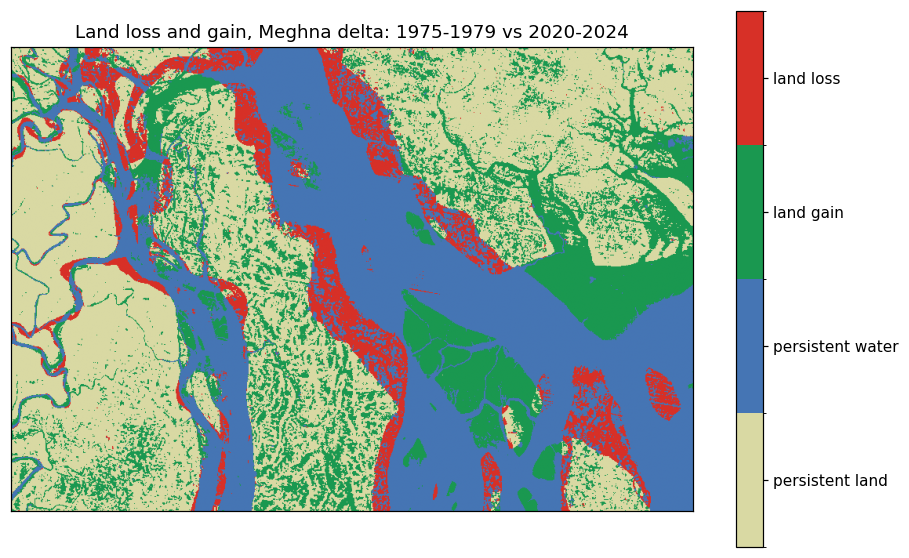

In [12]:
from matplotlib.colors import ListedColormap, BoundaryNorm

cmap = ListedColormap(["#d9d9a3", "#4575b4", "#1a9850", "#d73027"])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)
fig, ax = plt.subplots(figsize=(8.5, 6.8))
im = ax.imshow(change, cmap=cmap, norm=norm, origin="upper")
cb = plt.colorbar(im, ax=ax, ticks=[0, 1, 2, 3], shrink=0.75)
cb.ax.set_yticklabels(["persistent land", "persistent water", "land gain", "land loss"])
ax.set_xticks([]); ax.set_yticks([])
ax.set_title(f"Land loss and gain, Meghna delta: {EARLY_YEARS[0]}-{EARLY_YEARS[-1]} vs {LATE_YEARS[0]}-{LATE_YEARS[-1]}")
plt.tight_layout(); plt.show()

Land gain outweighs land loss by roughly three to one: the delta is building seaward, not
retreating. Gain concentrates in the wide band southeast of the main channel (new char land
accreting at the river mouth), while loss hugs the channel's own margins, where the river itself
has widened and cut into what was dry land fifty years ago. That combination (net accretion at
the mouth, erosion along the active channel) is the textbook signature of a sediment-rich delta
still being built by its river, and it matches the pattern NASA's Padma feature documents a
short distance upstream. The speckled pixels inside each large block are classification noise at
100 m resolution, not real pixel-scale change; read the map at the scale of the solid patches.


## Summary and Conclusion

In this analysis, we investigated changes in land and water in the Meghna delta region over a period of roughly 50 years, using satellite remote sensing data. By comparing averaged land classifications from the early 1970s to the early 2020s, we were able to map areas of persistent land, persistent water, land gain (accretion), and land loss (erosion).

The results indicate that the delta has been expanding seaward, with land gain significantly outpacing land loss. The accretion of new land is most prominent in the southeastern portion of the delta near the river mouth, while zones of land loss are concentrated along the active river channels where erosion occurs. This pattern is characteristic of an actively growing, sediment-rich delta system, further corroborated by previous studies and observed upstream phenomena.

In terms of area, land gain exceeds land loss by approximately a three to one ratio, resulting in a net increase in deltaic landmass. Much of the newly formed land consists of "char" islands, which arise and grow due to the deposition of river-borne sediment. The fine-scale pixel variation on the classification maps is largely attributable to classification uncertainty at 100 m resolution and should be interpreted with caution; the broader spatial trends and large patches provide a more reliable indication of real changes.

In summary, the Meghna delta remains a dynamic, growing landform, with human and ecological implications for habitat evolution, agricultural potential, hazard exposure, and long-term river processes. Continued monitoring using remote sensing will be crucial for understanding and managing these evolving landscapes.
